# URL exploration

I start with the data splits, then look for simple URL patterns and leakage.

In [1]:
from pathlib import Path
import json
import os
import re
import sys
from collections import Counter

# nbconvert starts here in notebooks/, but I want paths relative to the repo.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import data
from model import make
from preprocess import (STRUCTURE_NAMES, advanced_features, clean_url,
                        split_url, structure)

sets = {name: data.load(file) for name, file in {
    "train": "train", "test": "test", "external": "external_test"
}.items()}
train_clean, cleaning = data.clean_train(sets["train"])
audit = json.loads((ROOT / "reports/audit.json").read_text())

In [2]:
# Keep the existing audit summary beside the split-level tables.
display(pd.DataFrame([{"issue": key, "count": value}
                      for key, value in audit["train_issues"].items()]))
display(pd.DataFrame([cleaning]))

characteristics = [
    {"set": name, "feature": feature, **rates}
    for name, frame in {"train": train_clean, "test": sets["test"],
                        "external": sets["external"]}.items()
    for feature, rates in data.characteristics(frame).items()
]
display(pd.DataFrame(characteristics))

overlap_rows = [
    {"comparison": name, "level": level, **counts}
    for name, evaluation, training in [
        ("test", sets["test"], sets["train"]),
        ("external", sets["external"], sets["train"]),
    ]
    for level, counts in data.overlap(evaluation, training).items()
]
display(pd.DataFrame(overlap_rows))

# One structure row per cleaned training URL makes labels line up exactly.
structure_rows = []
for raw_url in train_clean.url:
    url = clean_url(raw_url)
    host, path = split_url(url)
    structure_rows.append(structure(url, host, path))
structure_frame = pd.DataFrame(structure_rows, columns=STRUCTURE_NAMES)
structure_frame["label"] = train_clean.label.to_numpy()
feature_corr = structure_frame.corr(numeric_only=True)["label"].drop("label")
display(feature_corr.sort_values(key=abs, ascending=False).to_frame("label_corr"))

,issue,count
0,exact_duplicate_rows,30
1,urls_with_both_labels,50
2,normalised_duplicate_rows,282
3,html_entity_rows,185
4,html_entity_rows_phishing,185
5,non_ascii_rows,5
6,uppercase_rows,2268
7,over_500_chars,20
8,hosts_with_both_labels,55
9,top_domains,"{'duilawyeryork.com': {'rows': 265, 'phish': 2..."


,rows_in,conflicting_keys,dropped_conflict_rows,dropped_duplicate_rows,rows_out,phishing_out,legit_out
0,8651,50,107,225,8319,4062,4257


,set,feature,legit,phish
0,train,has_path_or_query,0.626,0.815
1,train,starts_www,0.661,0.203
2,train,digit_in_host,0.032,0.228
3,train,3plus_host_labels,0.285,0.579
4,train,hyphen_in_host,0.074,0.227
5,train,credential_word,0.009,0.236
6,train,brand_word,0.022,0.148
7,train,html_entity,0.000,0.043
8,test,has_path_or_query,0.600,0.809
9,test,starts_www,0.685,0.209


,comparison,level,rows,share,phish_rows
0,test,exact_url,0,0.000,0
1,test,normalised_url,148,0.052,147
2,test,host,963,0.337,607
3,test,registered_domain,1194,0.418,762
4,external,exact_url,0,0.000,0
5,external,normalised_url,0,0.000,0
6,external,host,24,0.008,17
7,external,registered_domain,69,0.024,52


,label_corr
starts_www,-0.461730
url_digit_ratio,0.361868
log_suspicious_words,0.342195
has_query,0.307036
log_len_url,0.296680
log_host_digits,0.292940
log_path_equals,0.287834
log_brand_words,0.228414
log_len_path,0.220402
log_host_hyphens,0.215454


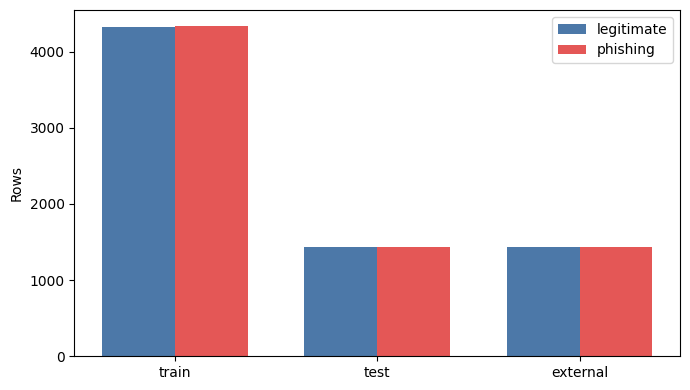

In [3]:
# Counts show the class balance in each supplied file.
fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(3)
for offset, label, color in [(-0.18, 0, "#4c78a8"), (0.18, 1, "#e45756")]:
    counts = [int((frame.label == label).sum()) for frame in sets.values()]
    ax.bar(x + offset, counts, width=0.36,
           label="legitimate" if label == 0 else "phishing", color=color)
ax.set_xticks(x, list(sets))
ax.set_ylabel("Rows")
ax.legend()
fig.tight_layout()
plt.show()
plt.close(fig)

The raw training file is almost exactly balanced (4,321 legitimate and 4,330 phishing); test and external each have 1,429 rows per class.

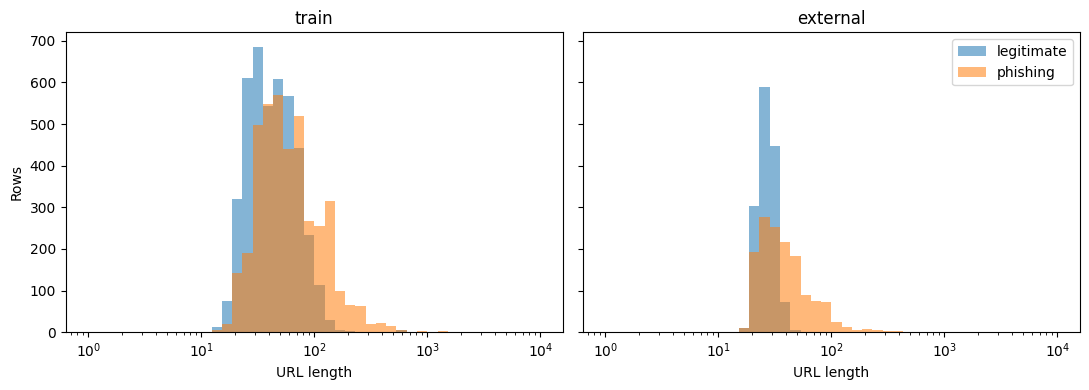

In [4]:
# The log x-axis leaves room for the short URLs and the long tail.
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for axis, name in zip(axes, ("train", "external")):
    frame = train_clean if name == "train" else sets[name]
    for label, group in frame.groupby("label"):
        axis.hist(group.url.str.len(), bins=np.logspace(0, 4, 45), alpha=0.55,
                  label="phishing" if label else "legitimate")
    axis.set_xscale("log")
    axis.set(title=name, xlabel="URL length")
axes[0].set_ylabel("Rows")
axes[-1].legend()
fig.tight_layout()
plt.show()
plt.close(fig)

Phishing URLs are longer on average: median length is 55 vs 42 in train and 35 vs 27 externally. External legitimate URLs stay especially short (95th percentile 36 characters).

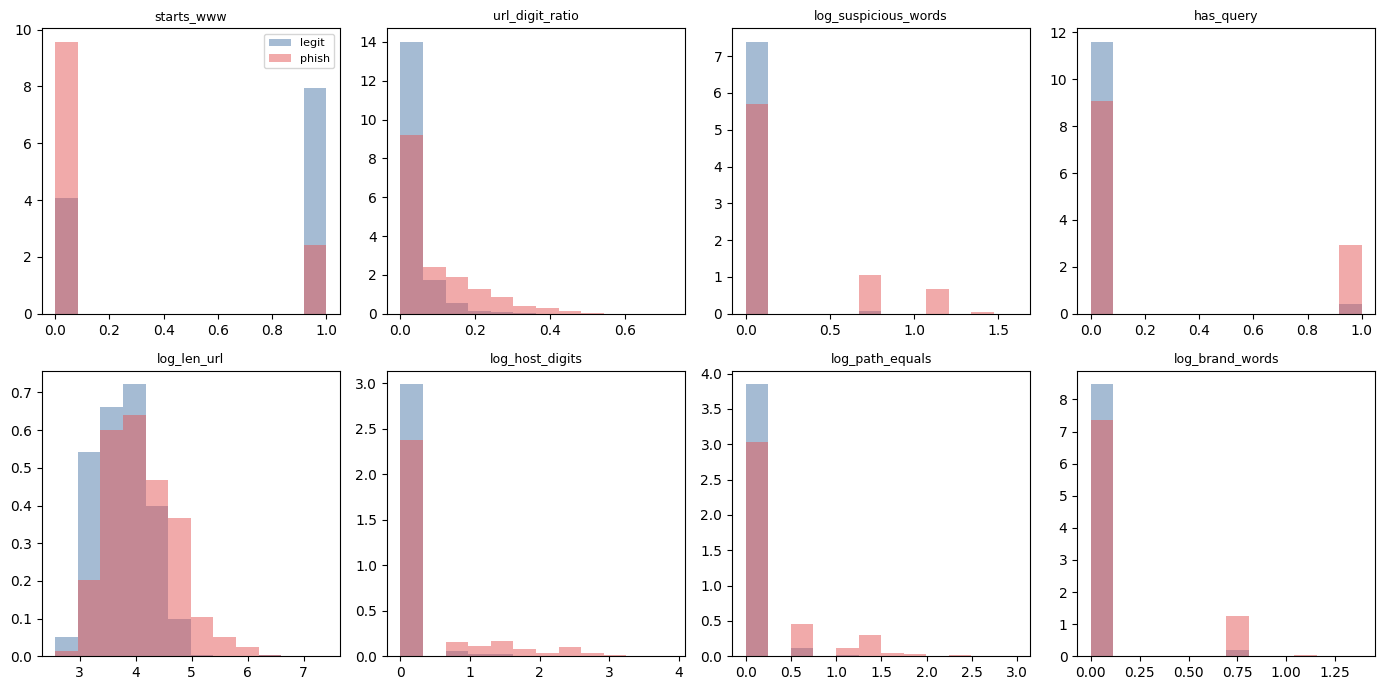

In [5]:
# Histograms keep sparse, mostly-zero features visible by class.
top_structure = feature_corr.abs().sort_values(ascending=False).head(8).index
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for axis, feature in zip(axes.flat, top_structure):
    bins = np.histogram_bin_edges(structure_frame[feature], bins=12)
    for label, color, name in ((0, "#4c78a8", "legit"),
                               (1, "#e45756", "phish")):
        axis.hist(structure_frame.loc[structure_frame.label == label, feature],
                  bins=bins, density=True, alpha=0.5, color=color, label=name)
    axis.set_title(feature, fontsize=9)
axes[0, 0].legend(fontsize=8)
fig.tight_layout()
plt.show()
plt.close(fig)

About 66% of legitimate URLs start with www, versus 20% of phishing URLs. Phishing URLs also have heavier positive tails for digit ratio and suspicious-word counts.

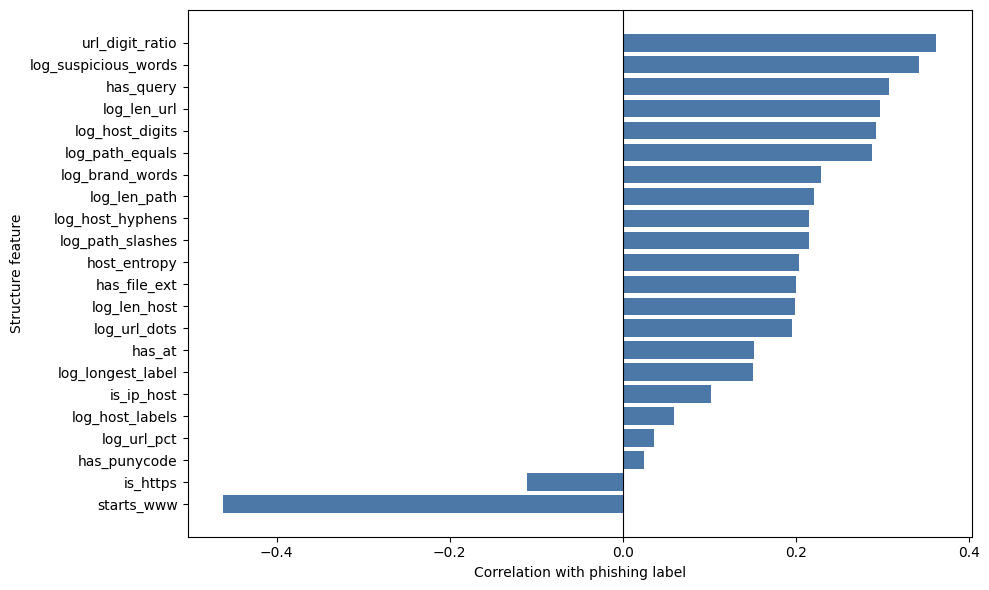

In [6]:
# Pearson correlation with a binary label is the point-biserial correlation.
ordered_corr = feature_corr.sort_values()
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(ordered_corr.index, ordered_corr.values, color="#4c78a8")
ax.axvline(0, color="black", linewidth=0.8)
ax.set(xlabel="Correlation with phishing label", ylabel="Structure feature")
fig.tight_layout()
plt.show()
plt.close(fig)

`starts_www` is the strongest negative correlation (-0.462); URL digit ratio (+0.362) and suspicious words (+0.342) are among the strongest positive signals.

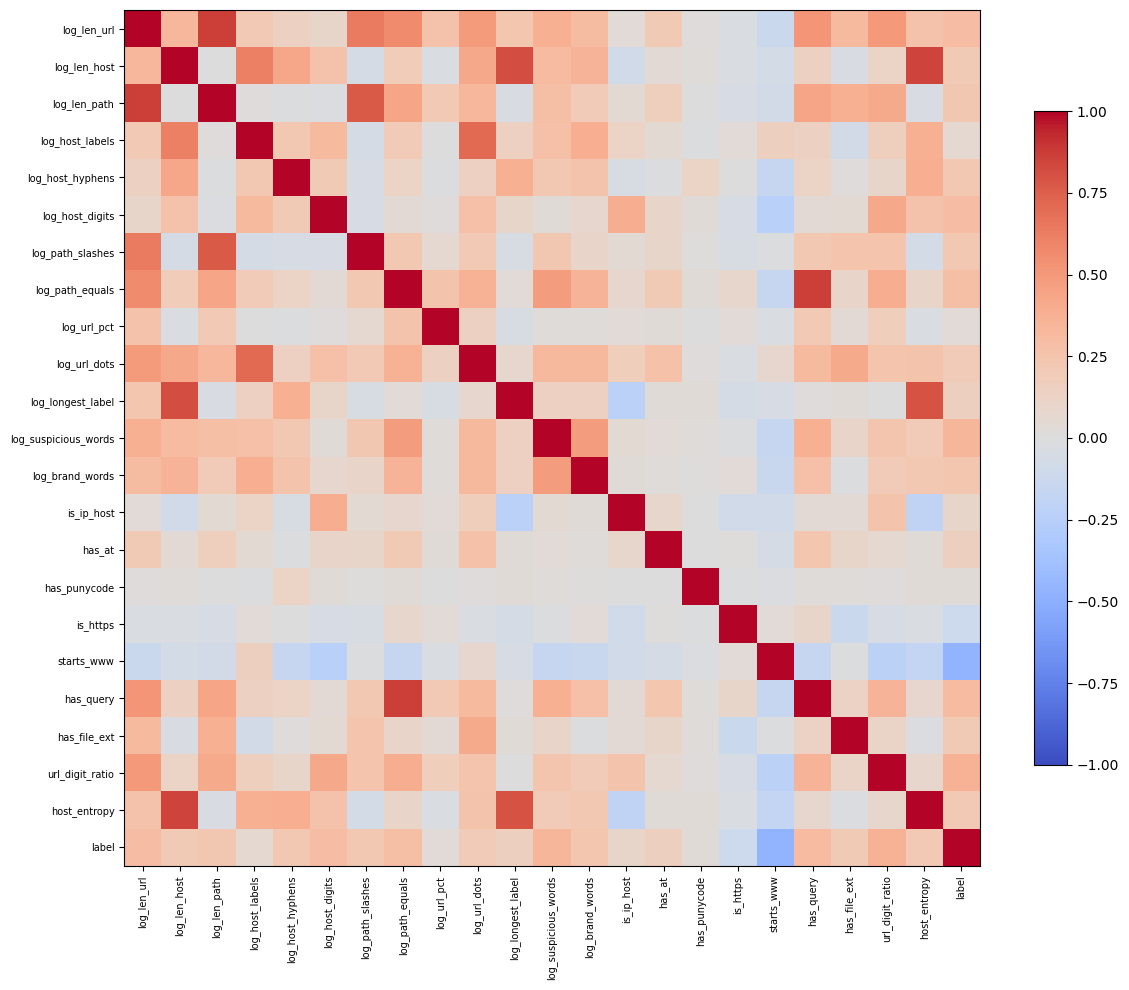

In [7]:
# Correlated structure fields can carry much the same information.
corr_matrix = structure_frame.corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(12, 10))
image = ax.imshow(corr_matrix, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_matrix)), corr_matrix.columns, rotation=90, fontsize=7)
ax.set_yticks(range(len(corr_matrix)), corr_matrix.index, fontsize=7)
fig.colorbar(image, ax=ax, fraction=0.03)
fig.tight_layout()
plt.show()
plt.close(fig)

`has_query` and `log_path_equals` correlate 0.86, and URL length with path length 0.87; most other structure-field pairs are weaker.

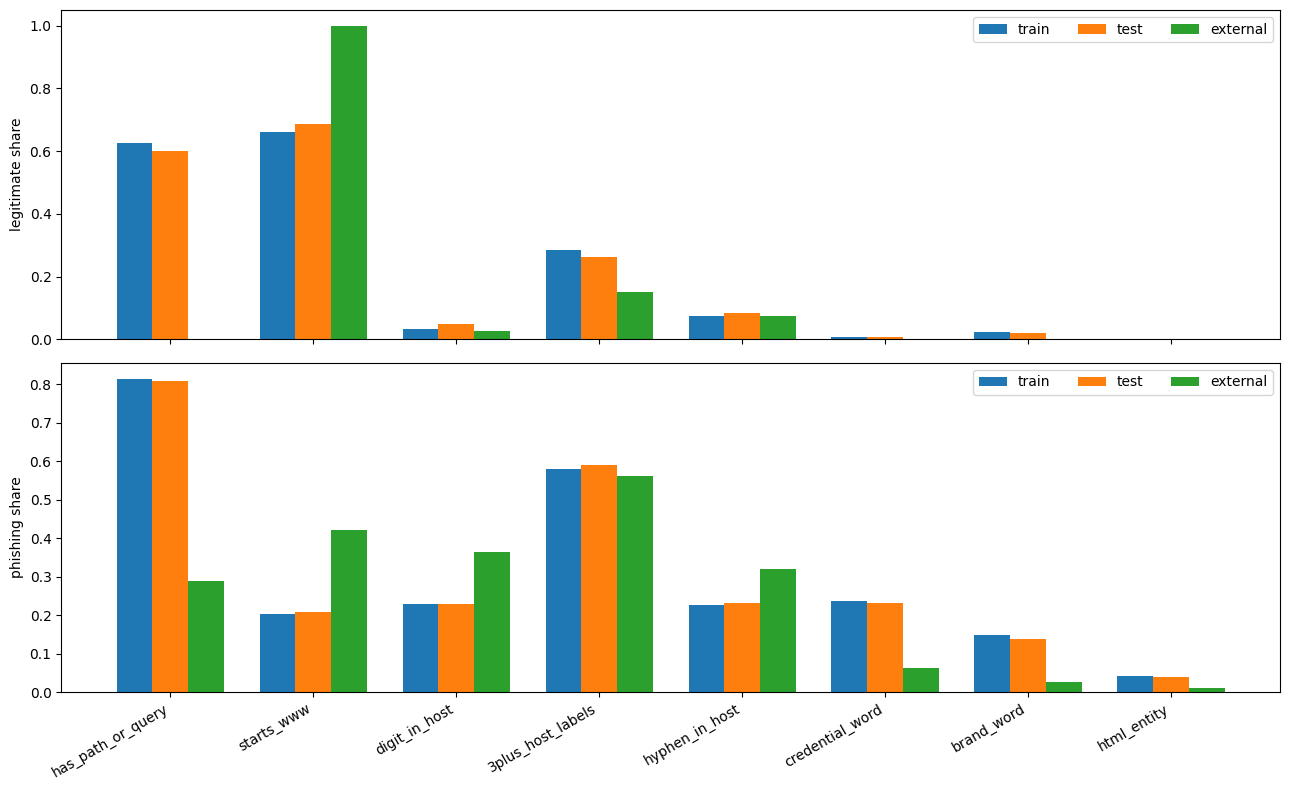

In [8]:
# Grouped bars make changes between the three data files easy to compare.
char_frame = pd.DataFrame(characteristics)
features = char_frame.feature.unique()
fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
for axis, label, column in zip(axes, ("legit", "phish"), ("legitimate", "phishing")):
    width = 0.25
    for i, name in enumerate(("train", "test", "external")):
        values = char_frame[char_frame["set"] == name].set_index("feature").loc[features, label]
        axis.bar(np.arange(len(features)) + (i - 1) * width, values,
                 width, label=name)
    axis.set_ylabel(f"{column} share")
    axis.legend(ncol=3)
axes[-1].set_xticks(np.arange(len(features)), features, rotation=30, ha="right")
fig.tight_layout()
plt.show()
plt.close(fig)

Train and test shares are close, but `has_path_or_query` falls from 63%/82% (legitimate/phishing) in train to 0%/29% externally. External legitimate URLs all start with www, compared with 66% in train.

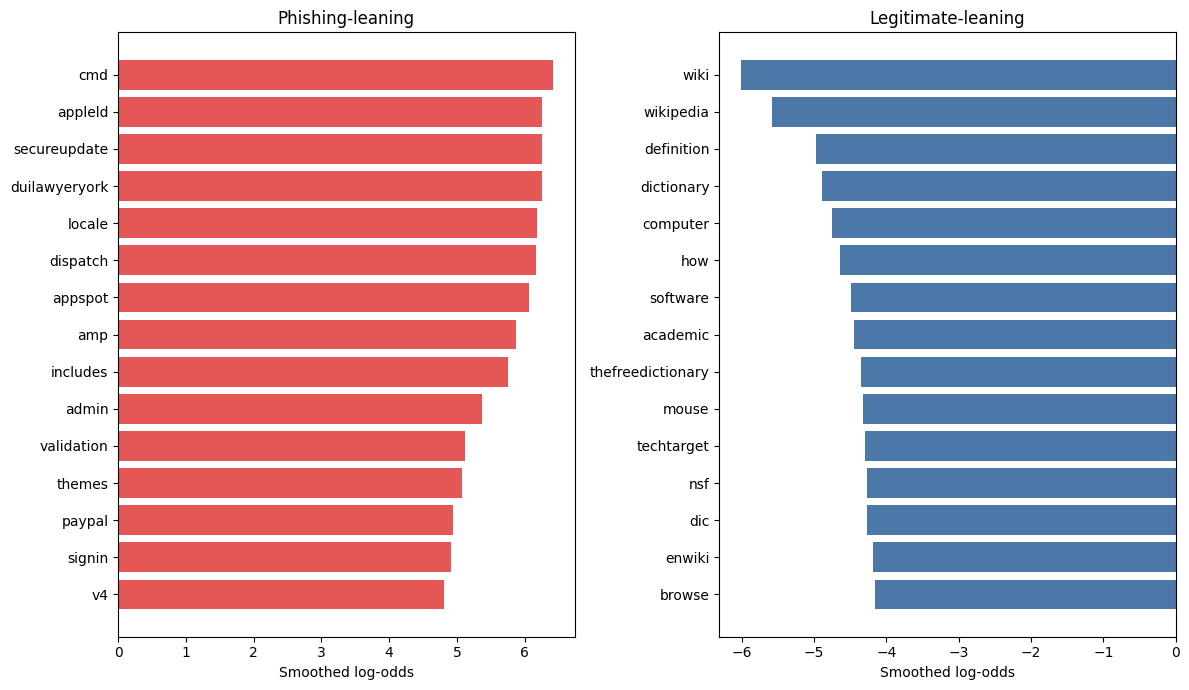

In [9]:
# Count each token once per URL, then smooth the class log-odds.
token_counts = {0: Counter(), 1: Counter()}
for row in train_clean.itertuples():
    tokens = set(re.findall(r"[a-z0-9]{2,}", row.url.lower()))
    tokens.update(re.findall(r"[a-z0-9]{2,}", row.host.lower()))
    tokens.difference_update({"http", "https", "www", "com", "org", "net"})
    token_counts[int(row.label)].update(tokens)
vocabulary = set(token_counts[0]) | set(token_counts[1])
alpha = 0.5
docs = {label: int((train_clean.label == label).sum()) for label in (0, 1)}
token_log_odds = {
    token: np.log((token_counts[1][token] + alpha) /
                  (docs[1] + alpha * len(vocabulary)))
           - np.log((token_counts[0][token] + alpha) /
                    (docs[0] + alpha * len(vocabulary)))
    for token in vocabulary
}
phish_tokens = sorted(token_log_odds, key=token_log_odds.get, reverse=True)[:15]
legit_tokens = sorted(token_log_odds, key=token_log_odds.get)[:15]
fig, axes = plt.subplots(1, 2, figsize=(12, 7))
axes[0].barh(phish_tokens[::-1], [token_log_odds[t] for t in phish_tokens[::-1]],
             color="#e45756")
axes[1].barh(legit_tokens[::-1], [token_log_odds[t] for t in legit_tokens[::-1]],
             color="#4c78a8")
axes[0].set(title="Phishing-leaning", xlabel="Smoothed log-odds")
axes[1].set(title="Legitimate-leaning", xlabel="Smoothed log-odds")
fig.tight_layout()
plt.show()
plt.close(fig)

The top phishing-leaning tokens are `cmd`, `secureupdate`, and `duilawyeryork`; the top legitimate-leaning tokens are `wiki`, `wikipedia`, and `definition`. These look dataset-specific, not like universal rules.

,set,level,rows,share,phish_rows
0,test,exact_url,0,0.000,0
1,test,normalised_url,148,0.052,147
2,test,host,963,0.337,607
3,test,registered_domain,1194,0.418,762
4,external,exact_url,0,0.000,0
5,external,normalised_url,0,0.000,0
6,external,host,24,0.008,17
7,external,registered_domain,69,0.024,52


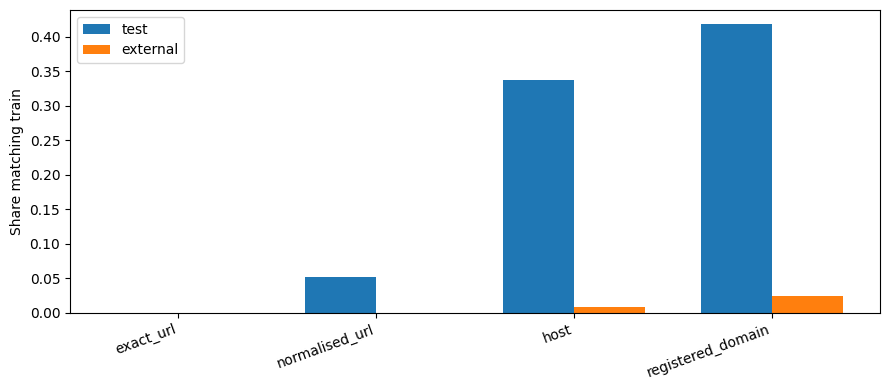

In [10]:
# Show the four matching levels as shares of each evaluation set.
overlap_frame = pd.DataFrame([
    {"set": name, "level": level, **counts}
    for name, evaluation in (("test", sets["test"]),
                             ("external", sets["external"]))
    for level, counts in data.overlap(evaluation, sets["train"]).items()
])
display(overlap_frame)
levels = list(data.overlap(sets["test"], sets["train"]))
fig, ax = plt.subplots(figsize=(9, 4))
width = 0.36
for i, name in enumerate(("test", "external")):
    values = overlap_frame[overlap_frame["set"] == name].set_index("level").loc[levels, "share"]
    ax.bar(np.arange(len(levels)) + (i - 0.5) * width, values,
           width, label=name)
ax.set_xticks(np.arange(len(levels)), levels, rotation=20, ha="right")
ax.set_ylabel("Share matching train")
ax.legend()
fig.tight_layout()
plt.show()
plt.close(fig)

Test has no exact URL matches but shares 41.8% of registered domains with train. External overlap is much lower: 2.4% by registered domain and zero exact or normalized URL matches.

I fit one quick LightGBM on all cleaned training rows to see where gain lands. This is an in-sample look, not the evaluation.

In [11]:
# Use the sweep's tree settings just to get a rough feature-group view.
quick_model = make("lightgbm", {
    "n_estimators": 300, "learning_rate": 0.05, "num_leaves": 63,
    "colsample_bytree": 0.3, "min_child_samples": 10,
})
quick_model.fit(advanced_features(train_clean.url), train_clean.label)
gain = quick_model.booster_.feature_importance(importance_type="gain")
assert len(gain) == 2**15 + 2**15 + 2**14 + len(STRUCTURE_NAMES)
block_gains = {
    "host n-grams": gain[:2**15].sum(),
    "path n-grams": gain[2**15:2**16].sum(),
    "word tokens": gain[2**16:2**16 + 2**14].sum(),
    "structure": gain[-len(STRUCTURE_NAMES):].sum(),
}
structure_gain = pd.Series(gain[-len(STRUCTURE_NAMES):], index=STRUCTURE_NAMES)
display(structure_gain.sort_values(ascending=False).head(15).to_frame("gain"))

,gain
log_suspicious_words,4131.893940
log_len_path,3345.899899
url_digit_ratio,3232.658449
log_path_slashes,2069.360834
log_host_digits,1641.098681
log_url_dots,1225.145965
log_len_url,1055.348112
log_host_labels,748.778231
has_query,630.047746
log_len_host,512.296956


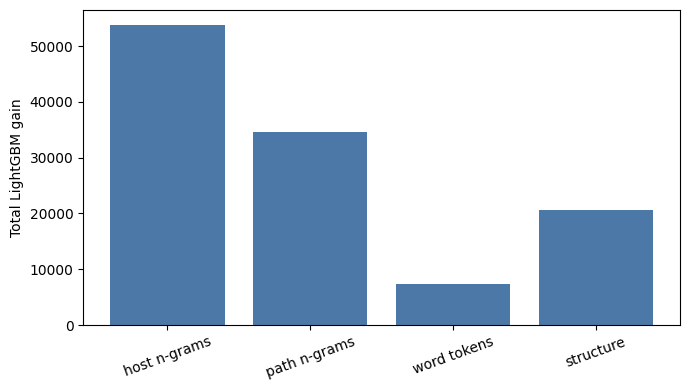

In [12]:
# Compare total gain across the four advanced feature blocks.
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(block_gains.keys(), block_gains.values(), color="#4c78a8")
ax.set_ylabel("Total LightGBM gain")
ax.tick_params(axis="x", rotation=20)
fig.tight_layout()
plt.show()
plt.close(fig)

Host n-grams lead by total gain, followed by path n-grams; the small structure block contributes more gain than word tokens in this fit.

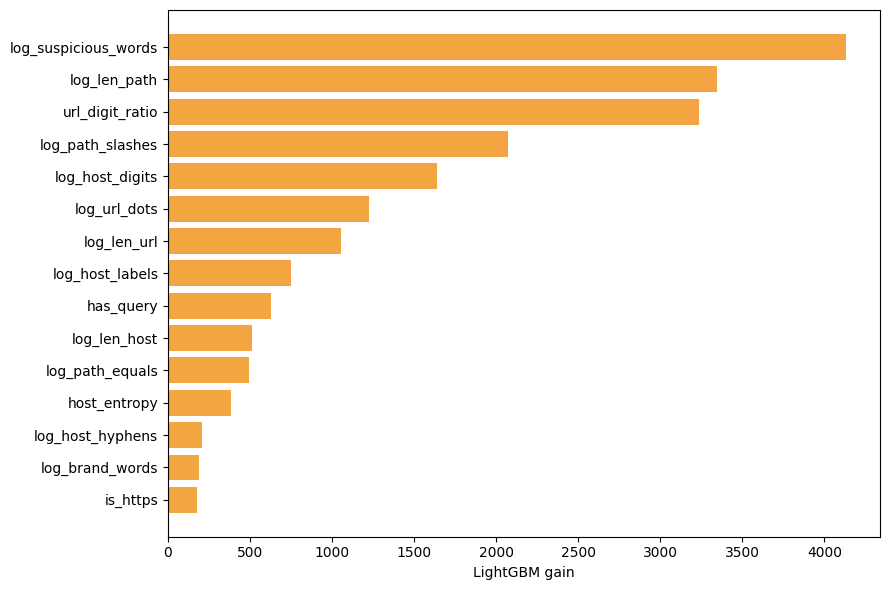

In [13]:
# Show the hand-built fields without the much wider hash blocks.
top_gain = structure_gain.sort_values().tail(15)
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top_gain.index, top_gain.values, color="#f2a541")
ax.set_xlabel("LightGBM gain")
fig.tight_layout()
plt.show()
plt.close(fig)

Suspicious-word count, path length and URL digit ratio are the three strongest structure fields by gain in this quick fit.